/Users/xubk/Desktop/机器学习古气候计/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 393/393 [00:17<00:00, 22.27it/s]


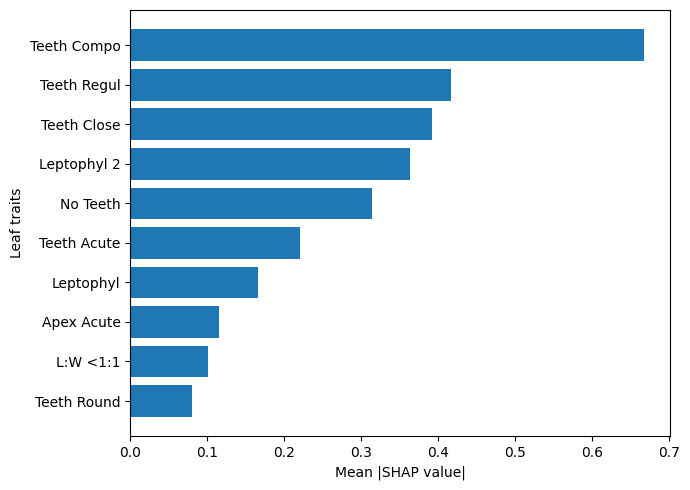

In [1]:
import joblib
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 读取模型
model = joblib.load("WMMT_CatBoost.joblib")

# 数据
file_path = "Global378+Tibet15+Fossil73_更正.xlsx"

# Modern calibration dataset (393 sites: 378 global + 15 Tibetan Plateau)
df_modern = pd.read_excel(file_path, sheet_name="plants")
# Fossil dataset (73 assemblages)
df_fossil = pd.read_excel(file_path, sheet_name="fossils")

feature_cols = [
    'Lobed', 'No Teeth', 'Teeth Regul', 'Teeth Close', 'Teeth Round', 'Teeth Acute', 'Teeth Compo',
    'Nanophyl', 'Leptophyl', 'Leptophyl 2', 'Microphyl 1', 'Microphyl 2', 'Microphyl 3',
    'Mesophyl 1', 'Mesophyl 2', 'Mesophyl 3', 'Apex Emargi', 'Apex Round', 'Apex Acute', 'Apex Attenu',
    'Base Cordat', 'Base Round', 'Base Acute', 'L:W <1:1', 'L:W 1-2:1', 'L:W 2-3:1', 'L:W 3-4:1',
    'L:W >4:1', 'Obovate', 'Elliptic', 'Ovate'
]


X = df_modern[feature_cols]

# SHAP
background = shap.sample(X, 100, random_state=42)

explainer = shap.KernelExplainer(
    model.predict,
    background
)

shap_values = explainer.shap_values(X)

importance = np.abs(shap_values).mean(axis=0)

imp_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
).head(10)

plt.style.use("default")

fig, ax = plt.subplots(figsize=(7,5))

ax.barh(
    imp_df["Feature"][::-1],
    imp_df["Importance"][::-1]
)

ax.set_xlabel("Mean |SHAP value|")
ax.set_ylabel("Leaf traits")

plt.tight_layout()

plt.savefig(
    "WMMT_SHAP_Importance.svg",
    format="svg",
    bbox_inches="tight"
)

/Users/xubk/Desktop/机器学习古气候计/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 393/393 [00:17<00:00, 22.11it/s]


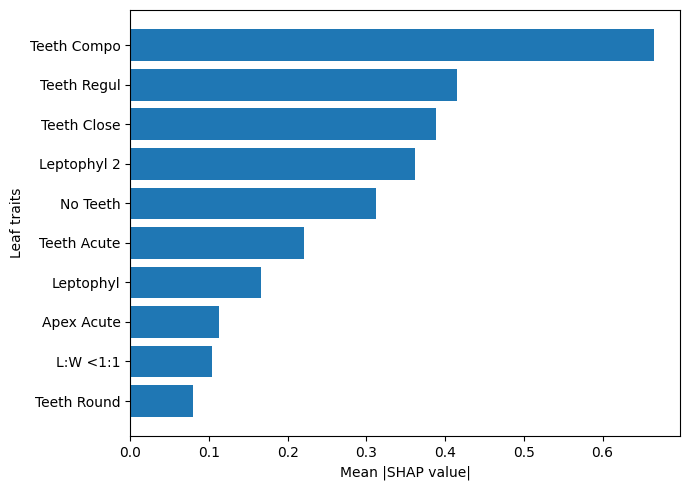

In [1]:
import joblib
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 读取模型
model = joblib.load("GROWSEAS_CatBoost.joblib")

# 数据
file_path = "Global378+Tibet15+Fossil73_更正.xlsx"

# Modern calibration dataset (393 sites: 378 global + 15 Tibetan Plateau)
df_modern = pd.read_excel(file_path, sheet_name="plants")
# Fossil dataset (73 assemblages)
df_fossil = pd.read_excel(file_path, sheet_name="fossils")

feature_cols = [
    'Lobed', 'No Teeth', 'Teeth Regul', 'Teeth Close', 'Teeth Round', 'Teeth Acute', 'Teeth Compo',
    'Nanophyl', 'Leptophyl', 'Leptophyl 2', 'Microphyl 1', 'Microphyl 2', 'Microphyl 3',
    'Mesophyl 1', 'Mesophyl 2', 'Mesophyl 3', 'Apex Emargi', 'Apex Round', 'Apex Acute', 'Apex Attenu',
    'Base Cordat', 'Base Round', 'Base Acute', 'L:W <1:1', 'L:W 1-2:1', 'L:W 2-3:1', 'L:W 3-4:1',
    'L:W >4:1', 'Obovate', 'Elliptic', 'Ovate'
]


X = df_modern[feature_cols]

# SHAP
background = shap.sample(X, 100, random_state=42)

explainer = shap.KernelExplainer(
    model.predict,
    background
)

shap_values = explainer.shap_values(X)

importance = np.abs(shap_values).mean(axis=0)

imp_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
).head(10)

plt.style.use("default")

fig, ax = plt.subplots(figsize=(7,5))

ax.barh(
    imp_df["Feature"][::-1],
    imp_df["Importance"][::-1]
)

ax.set_xlabel("Mean |SHAP value|")
ax.set_ylabel("Leaf traits")

plt.tight_layout()

plt.savefig(
    "GROWSEAS_SHAP_Importance.svg",
    format="svg",
    bbox_inches="tight"
)